# 38 · 데이터 변형과 불변성

📎 **이번 질문** · 사진의 배경을 바꾸어도 같은 과일이라고 배울 수 있을까요?

준비물: 05 합성곱, 10 그래프의 순열, 15 구조 선택; 계산에는 03 MLP와 04 Adam. NumPy·CPU float64만 사용하며 다른 노트북 실행 상태나 다운로드에 의존하지 않습니다. 과일의 상태와 촬영 조건을 단순화한 합성 자료로 수식부터 실제 학습까지 연결합니다.

| 표시 | 뜻 | 읽는 법 |
|---|---|---|
| 🔑 | 핵심 | 축과 기울기 경로를 씁니다 |
| 🔍 | 확인 | 그림·손계산·독립 평가를 대조합니다 |
| 📎 | 참고 | 처음 나온 용어·관용구를 풀이합니다 |
| ✏️ | 연습 | 한두 줄을 채우고 검사합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 변형은 입력을 바꾸는 분포이며, 무엇을 보존할지는 과제가 정합니다.
2. 불변성과 등변성은 다릅니다. 양성 쌍이라는 이름만으로 의미 보존이 보장되지 않습니다.
3. 같은 초기값·예산에서 학습하고 독립 평가와 표현 통계를 함께 봅니다.

[학습 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/augmentation_plots.py)

In [1]:
# 준비 셀: 그림과 독립 미분 검산 도구입니다.
import sys
from pathlib import Path
import numpy as np
project_root = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient,rel_error
from src.utils.augmentation_plots import plot_panels,plot_curves,plot_points
setup_plots()

'Arial Unicode MS'

## 🔑 1. 같은 과일이라는 조건부터 정합니다

**이 절에서 가져갈 것:** 변형 뒤에도 보존되어야 하는 정답을 먼저 적습니다.

과일의 상태를 $x_0$, 촬영 배경의 밝기를 $x_1$로 단순화합니다. $x_0>0$인 과일이 익었다는 정답 $y=1[x_0>0]$을 정합니다. 이 규칙에서는 배경 부호를 뒤집어도 정답이 같습니다. 상태 부호를 뒤집고 옛 정답을 붙이면 잘못된 자료가 됩니다. 이는 우리가 정한 합성 과제의 정확한 규칙이며 실제 색 변화가 모든 과일에서 안전하다는 뜻은 아닙니다.

> **용어**
> - **데이터 증강(data augmentation)**은 관측에 무작위 변형 $T_\xi$를 적용해 학습 입력을 만드는 방법입니다.
> - **라벨(label)**은 이 과제에서 익음 여부의 정답 0 또는 1입니다.
> - **불변성(invariance)**은 변형 전후 출력이 같은 성질 $f(Tx)=f(x)$입니다.

행으로 저장한 $X:(N,2)$에 $Y=XA+b$를 적용합니다. $A:(2,2)$의 열 j가 새 좌표 j를 만듭니다. 배경 반전 $A=\operatorname{diag}(1,-1)$은 y를 보존하지만 90도 회전 $A=\left[\begin{smallmatrix}0&1\\-1&0\end{smallmatrix}\right]$은 보통 보존하지 않습니다.

> **코드** · `X[:,0]`은 모든 과일의 상태 열입니다. `[:,None]`은 길이 N 배열을 (N,1) 열로 바꿉니다. `np.column_stack`은 여러 열을 한 표에 붙입니다.

In [2]:
example=np.array([[1.,2.],[-2.,1.],[.5,-1.]])
background_flip=np.diag([1.,-1.])
rotation=np.array([[0.,1.],[-1.,0.]])
flip_example=example@background_flip
rotate_example=example@rotation
label_table=np.column_stack([example[:,0]>0,flip_example[:,0]>0,rotate_example[:,0]>0]).astype(float)

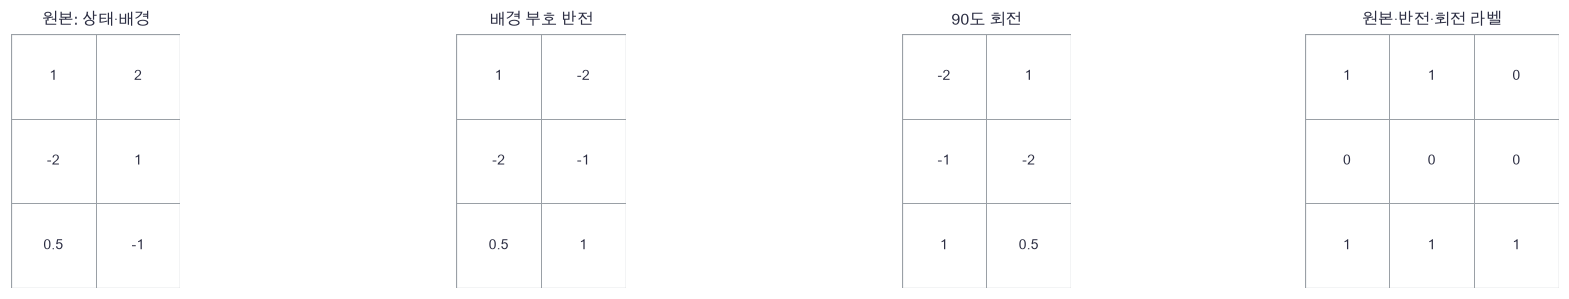

In [3]:
plot_panels([example,flip_example,rotate_example,label_table],['원본: 상태·배경','배경 부호 반전','90도 회전','원본·반전·회전 라벨'])

🔍 **확인** · 마지막 표는 변형한 좌표에 정답 규칙을 다시 적용한 결과입니다. 회전은 이 과제의 익음 정보를 바꿉니다. 숫자 6과 9의 회전이나 방향 분류 문제도 같은 판단이 필요합니다.

In [4]:
def affine_loop(X,A,b):
    """행 저장 선형 변형의 반복문. X:(N,D), A:(D,D), b:(D,) → (N,D)."""
    Y=np.zeros_like(X)
    for n in range(len(X)):
        for j in range(X.shape[1]):
            Y[n,j]=b[j]
            for k in range(X.shape[1]):
                Y[n,j]+=X[n,k]*A[k,j]
    return Y

In [5]:
def affine_view(X,A,b):
    """Y=XA+b의 벡터화. 행마다 하나의 관측입니다."""
    return X@A+b

In [6]:
# 쓰는 것: background_flip (1절) · example (1절)
hand=np.array([[1.,-2.],[-2.,-1.],[.5,1.]])
np.testing.assert_allclose(affine_loop(example,background_flip,np.zeros(2)),hand)  # 검산: 좌표별 손계산
np.testing.assert_allclose(affine_view(example,background_flip,np.zeros(2)),hand)  # 검산: 벡터화 = 손계산
print('손계산·반복문·벡터화가 일치합니다.')

손계산·반복문·벡터화가 일치합니다.


### ✏️ 연습 1 · 변형 뒤 정답을 다시 읽기

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

상태 열의 엄격한 양수 여부를 0·1로 반환하세요.

In [7]:
def exercise_labels(X):
    """상태 열의 엄격한 양수 여부를 0·1로 반환하세요."""

    ### 구현할 내용: 상태 열의 엄격한 양수 여부를 0·1로 반환하세요.
    raise NotImplementedError
    return labels

In [8]:
def check_labels(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_array_equal(candidate(np.array([[-2.,9.],[0.,-2.],[1.,0.]])),[0,0,1])  # 검산: 부호 기준 0,0,1
    print("연습 1: 독립 기준값과 일치합니다.")

run_check(check_labels,exercise_labels,hint="상태 열의 엄격한 양수 여부를 0·1로 반환하세요.")

☐ exercise_labels: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 상태 열의 엄격한 양수 여부를 0·1로 반환하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
labels = (X[:,0]>0).astype(int)
```

</details>

## 🔑 2. 두 번 뽑은 변형이 양성 쌍을 만듭니다

**이 절에서 가져갈 것:** 같은 원본에서 독립 변형을 뽑되 변형 강도와 보존 정보는 별도로 확인합니다.

같은 과일을 배경 조명이 다른 두 번의 촬영으로 봅니다. $T_\epsilon(x)=(x_0,x_1+\sigma\epsilon)$, $\epsilon\sim N(0,1)$입니다. 같은 원본을 공유하는 $V_1,V_2$는 주변적으로 독립이 아닙니다. **원본을 고정했을 때** 두 잡음만 독립입니다.

> **용어**
> - **뷰(view)**는 한 원본에 변형을 적용한 관측입니다.
> - **양성 쌍(positive pair)**은 같은 원본으로부터 만들어 서로 대응한다고 지정한 두 뷰입니다. 이 명칭은 라벨 보존의 증명이 아닙니다.
> - **변형 강도 σ**는 배경 잡음의 표준편차입니다. 크다고 항상 좋은 것은 아닙니다.

두 뷰의 배경 차이는 $\sigma(\epsilon_1-\epsilon_2)$이므로 $E[(V_{1,1}-V_{2,1})^2]=2\sigma^2$입니다. 상태 축의 차이는 0입니다. 새로운 색·회전·crop에도 먼저 어떤 정보가 사라지는지 확인해야 합니다.

> **코드** · `default_rng(seed)`는 재현 가능한 난수기를 만듭니다. `normal(size=...)`은 표준정규 잡음을, `choice([-1.,1.])`은 두 부호를 뽑습니다. `_`는 사용하지 않는 반환값입니다.

In [9]:
fixed=np.array([[.5,1.]])
noise_pair=np.array([[-1.,.5],[1.,-.5],[0.,1.]])
view_one=np.repeat(fixed,3,axis=0)+np.column_stack([np.zeros(3),noise_pair[:,0]])
view_two=np.repeat(fixed,3,axis=0)+np.column_stack([np.zeros(3),noise_pair[:,1]])
pair_gap=(view_one-view_two)**2

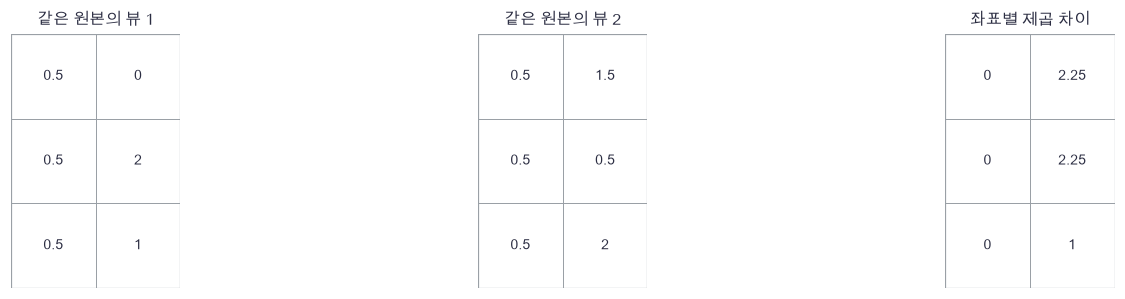

In [10]:
plot_panels([view_one,view_two,pair_gap],['같은 원본의 뷰 1','같은 원본의 뷰 2','좌표별 제곱 차이'])

🔍 **확인** · 상태 차이는 항상 0입니다. 배경 차이가 커지는 것이 목적 자체는 아닙니다. 두 뷰에 같은 잡음을 재사용하면 차이가 0이 되어 독립 변형을 구현하지 못합니다.

In [11]:
def draw_views(X,strength,rng,break_label=False):
    """배경 잡음과 선택적인 상태 부호 반전. X:(N,2) → 변형, 입력 미분계수."""
    multiplier=np.ones_like(X)
    if break_label:
        multiplier[:,0]=rng.choice([-1.,1.],size=len(X))
    noise=np.zeros_like(X)
    noise[:,1]=strength*rng.normal(size=len(X))
    return X*multiplier+noise,multiplier

In [12]:
fixed_many=np.repeat(fixed,20000,axis=0)
pair_rng=np.random.default_rng(386)
view_a,_=draw_views(fixed_many,.7,pair_rng)
view_b,_=draw_views(fixed_many,.7,pair_rng)
empirical=np.mean((view_a[:,1]-view_b[:,1])**2)
np.testing.assert_array_equal(view_a[:,0],fixed_many[:,0])  # 검산: 상태는 정확히 보존
assert abs(empirical-2*.7**2)<.04, '독립 잡음 차이의 2차 모멘트가 기대값에 가까워야 합니다'
print('관측 제곱 거리',round(empirical,3),'· 이론',2*.7**2)

관측 제곱 거리 0.97 · 이론 0.9799999999999999


### ✏️ 연습 2 · 행마다 쌍의 거리를 계산하기

같은 행끼리의 제곱 거리를 (N,)으로 반환하세요.

In [13]:
def exercise_pair_distance(A,B):
    """같은 행끼리의 제곱 거리를 (N,)으로 반환하세요."""

    ### 구현할 내용: 같은 행끼리의 제곱 거리를 (N,)으로 반환하세요.
    raise NotImplementedError
    return dist

In [14]:
def check_pair_distance(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,2.],[3.,4.]]),np.array([[0.,0.],[3.,1.]])),[5.,9.])  # 검산: 1+4, 0+9
    print("연습 2: 독립 기준값과 일치합니다.")

run_check(check_pair_distance,exercise_pair_distance,hint="같은 행끼리의 제곱 거리를 (N,)으로 반환하세요.")

☐ exercise_pair_distance: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 같은 행끼리의 제곱 거리를 (N,)으로 반환하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dist = ((A-B)**2).sum(axis=1)
```

</details>

## 🔑 3. 순서를 바꾸면 출력은 어떻게 바뀌어야 하나요?

**이 절에서 가져갈 것:** 원소별 출력은 함께 바뀌고 집합 출력은 그대로여야 합니다.

상자 안 과일 세 개의 목록 순서를 바꿉니다. 각 과일의 상태 점수는 그 과일을 따라 움직입니다. 상자 전체의 평균 상태는 바뀌지 않습니다.

> **용어** · **등변성(equivariance)**은 입력 변형과 같은 방식으로 출력이 변하는 $h(PX)=Ph(X)$입니다. 순열 행렬 P는 원소 순서를 바꿉니다. **풀링(pooling)**은 여기서 원소 축의 평균을 내어 상자당 특징 하나를 만드는 연산입니다.

$X:(B,K,D)$에서 B는 상자 수, K는 과일 수입니다. 공유 함수 $H=\tanh(XW):(B,K,F)$, $g=K^{-1}\sum_kH_k:(B,F)$라면 $H$는 순열 등변이고 g는 불변입니다. 이 평균은 원소 순서 정보와 전체 중복 횟수를 잃습니다. 순서가 의미인 문장·시계열에는 이 가정이 맞지 않을 수 있습니다. 그래프를 재정렬할 때에는 노드 특징과 adjacency의 두 축을 함께 바꿔야 합니다(10·21번).

> **코드** · `X[:,order,:]`는 상자마다 같은 순열을 적용합니다. `mean(axis=1)`은 과일 축만 없앱니다. `np.repeat`는 같은 값을 지정한 횟수 복제합니다.

In [15]:
fruit_box=np.array([[[1.,2.],[-2.,1.],[.5,-1.]]])
shared_w=np.array([[.5,-.2],[.1,.4]])
order=np.array([2,0,1])
features=np.tanh(fruit_box@shared_w)
reordered=features[:,order,:]
box_means=np.concatenate([features.mean(axis=1),reordered.mean(axis=1)],axis=0)

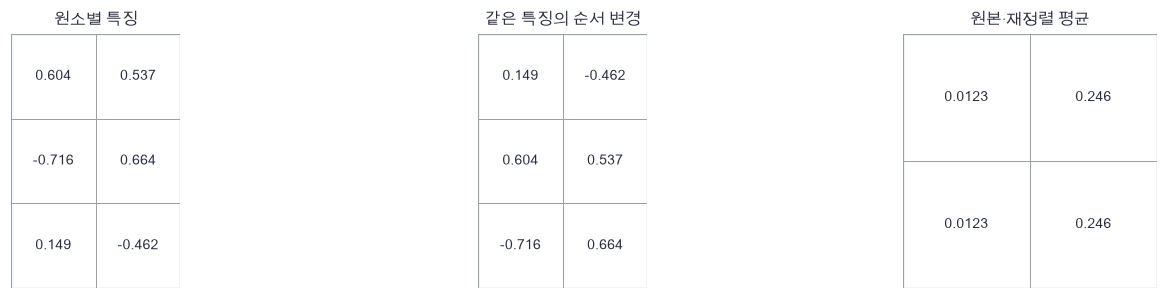

In [16]:
plot_panels([features[0],reordered[0],box_means],['원소별 특징','같은 특징의 순서 변경','원본·재정렬 평균'])

🔍 **확인** · 첫 두 표는 행 순서만 다르고 마지막 두 행은 같습니다. 상수 함수도 불변이므로 불변성 검산만으로 쓸모 있는 표현이라고 판단할 수 없습니다.

In [17]:
def set_encode(X,W):
    """원소 공유 tanh 뒤 평균. X:(B,K,D), W:(D,H) → 원소 특징, 집합 특징."""
    H=np.tanh(X@W)
    return H,H.mean(axis=1)

In [18]:
encoded,pooled=set_encode(fruit_box,shared_w)
changed,pooled_changed=set_encode(fruit_box[:,order,:],shared_w)
np.testing.assert_allclose(changed,encoded[:,order,:])  # 검산: 원소 출력 등변성
np.testing.assert_allclose(pooled_changed,pooled)  # 검산: 평균 출력 불변성
_,duplicated=set_encode(np.repeat(fruit_box,2,axis=1),shared_w)
np.testing.assert_allclose(duplicated,pooled)  # 검산: 전체 원소 복제는 평균에서 구분되지 않음
print('순열 등변·불변 및 중복 정보 소실을 확인했습니다.')

순열 등변·불변 및 중복 정보 소실을 확인했습니다.


### ✏️ 연습 3 · 평균의 기울기를 원소에 나누기

상자 평균의 상류 기울기 g:(B,F)를 K개 원소에 똑같이 나누세요.

In [19]:
def exercise_pool_backward(g,K):
    """상자 평균의 상류 기울기 g:(B,F)를 K개 원소에 똑같이 나누세요."""

    ### 구현할 내용: 상자 평균의 상류 기울기 g:(B,F)를 K개 원소에 똑같이 나누세요.
    raise NotImplementedError
    return dH

In [20]:
def check_pool_backward(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[6.,-3.]]),3),[[[2.,-1.],[2.,-1.],[2.,-1.]]])  # 검산: 세 원소에 1/3씩
    print("연습 3: 독립 기준값과 일치합니다.")

run_check(check_pool_backward,exercise_pool_backward,hint="상자 평균의 상류 기울기 g:(B,F)를 K개 원소에 똑같이 나누세요.")

☐ exercise_pool_backward: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 상자 평균의 상류 기울기 g:(B,F)를 K개 원소에 똑같이 나누세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dH = np.repeat(g[:,None,:]/K,K,axis=1)
```

</details>

## 🔑 4. 변형한 입력에서 실제 손실을 미분합니다

**이 절에서 가져갈 것:** 무작위 변형을 고정한 뒤 모델과 입력 경로를 모두 미분합니다.

배경이 달라진 과일을 보고 익음 점수를 냅니다. 이 절은 **지도학습 분류기**로 변형의 효과를 분리합니다. 양성 쌍을 직접 학습하는 대조 목적은 39번입니다.

> **용어**
> - **은닉 표현 H**는 입력에서 계산한 중간 특징입니다. $H:(N,F)$입니다.
> - **logit z**는 sigmoid를 적용하기 전 실수 점수입니다. $z:(N,1)$입니다.
> - **binary cross entropy(BCE)**는 맞는 정답의 확률이 높아지도록 하는 이진 분류 손실입니다.

$$V=X\odot M+E,\quad U=VW+b,\quad H=\tanh U,\quad z=Hv+c,$$
$$L=N^{-1}\sum_n[\log(1+e^{z_n})-y_nz_n],\quad G=(\operatorname{sigmoid}z-y)/N.$$

$M,E$는 이번 미분 동안 고정합니다. $d_v=H^TG$, $d_c=\sum_nG$, $d_U=(Gv^T)\odot(1-H^2)$, $d_W=V^Td_U$, $d_b=\sum_nd_U$, $d_X=(d_UW^T)\odot M$입니다. 변형의 무작위 선택 자체를 미분하지 않습니다. 배경 덧셈의 입력 미분은1, 상태 반전의 미분은−1입니다.

> **코드** · `logaddexp(0,z)`는 overflow 없이 $\log(1+e^z)$를 계산합니다. 사전 `p['W']`는 이름별 파라미터 배열입니다. `a.copy()`로 원본과 독립된 배열을 만듭니다.

In [21]:
small_x=np.array([[.5,1.],[-.4,-1.]])
small_m=np.array([[-1.,1.],[1.,1.]])
small_e=np.array([[0.,.2],[0.,-.1]])
small_view=small_x*small_m+small_e
small_u=small_view@np.array([[.3],[-.2]])
small_h=np.tanh(small_u)
small_logits=small_h*.4

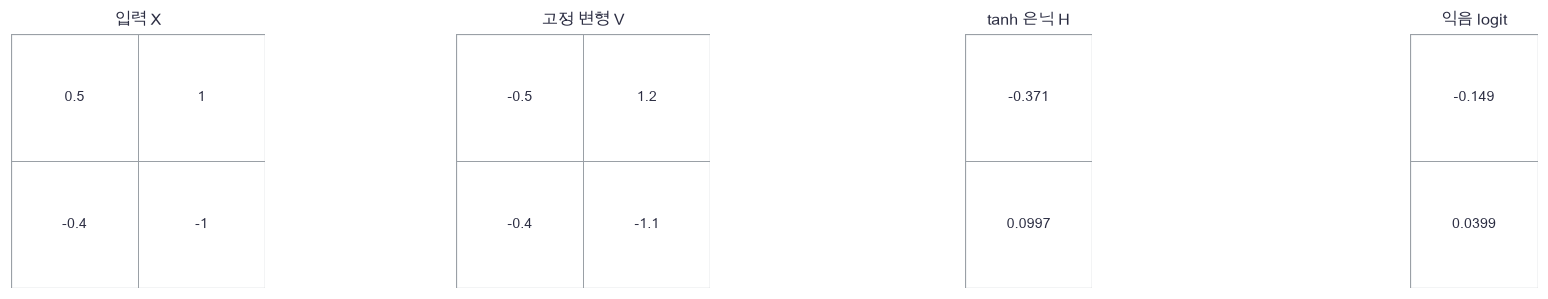

In [22]:
plot_panels([small_x,small_view,small_h,small_logits],['입력 X','고정 변형 V','tanh 은닉 H','익음 logit'])

🔍 **확인** · 첫 과일의 상태 부호가 뒤집혔습니다. 미분은 계산 그래프에 대해 맞을 수 있어도 이 변형이 정답을 보존하는지는 별개의 문제입니다.

In [23]:
def init_model(seed=380,hidden=8):
    """2→H→1 tanh 분류기를 초기화합니다."""
    rng=np.random.default_rng(seed)
    return {'W':rng.normal(0,.4,(2,hidden)),'b':np.zeros(hidden),
            'v':rng.normal(0,.3,(hidden,1)),'c':np.zeros(1)}

In [24]:
def model_forward(X,p):
    """H=tanh(XW+b), logits=Hv+c. X:(N,2) → (N,1), cache."""
    H=np.tanh(X@p['W']+p['b'])
    return H@p['v']+p['c'],(X,H)

In [25]:
def bce_loss(logits,y):
    """안정적인 표본 평균 binary CE와 logits 미분. 둘 다 (N,1)."""
    probability=np.exp(-np.logaddexp(0.,-logits))
    loss=np.mean(np.logaddexp(0.,logits)-y*logits)
    return loss,(probability-y)/len(y)

In [26]:
def model_backward(dlogits,cache,p):
    """모든 파라미터와 입력에 대한 연쇄법칙을 계산합니다."""
    X,H=cache
    dH=dlogits@p['v'].T
    dU=dH*(1-H**2)
    grads={'v':H.T@dlogits,'c':dlogits.sum(axis=0),
           'W':X.T@dU,'b':dU.sum(axis=0)}
    return grads,dU@p['W'].T

In [27]:
# 쓰는 것: init_model (4절) · small_e (4절) · small_m (4절)
probe=init_model(387,hidden=3)
probe_x=np.array([[.5,1.],[-.4,-1.]])
probe_y=np.array([[1.],[0.]])
probe_m=small_m.copy()
probe_e=small_e.copy()
probe_logits,probe_cache=model_forward(probe_x*probe_m+probe_e,probe)
probe_loss,probe_g=bce_loss(probe_logits,probe_y)
analytic,input_view_grad=model_backward(probe_g,probe_cache,probe)
input_grad=input_view_grad*probe_m

In [28]:
def probe_objective():
    """고정 변형을 포함한 전체 BCE를 중심차분합니다."""
    # 쓰는 것: model_forward (4절)
    logits,_=model_forward(probe_x*probe_m+probe_e,probe)
    return bce_loss(logits,probe_y)[0]

In [29]:
errors=[]
for key in probe:
    numeric=numerical_gradient(probe_objective,probe[key])
    np.testing.assert_allclose(analytic[key],numeric,atol=2e-8,rtol=2e-5)  # 검산: 모든 파라미터의 중심차분
    errors.append(rel_error(analytic[key],numeric))
numeric_x=numerical_gradient(probe_objective,probe_x)
np.testing.assert_allclose(input_grad,numeric_x,atol=2e-8,rtol=2e-5)  # 검산: 변형을 지난 입력의 중심차분
print('전체 파라미터·입력 검산, 최대 상대오차',max(errors+[rel_error(input_grad,numeric_x)]))

전체 파라미터·입력 검산, 최대 상대오차 4.339147260237784e-09


### ✏️ 연습 4 · 부호 반전을 통과하는 기울기

V=X*M+E에서 고정 M,E를 통과하는 입력 기울기를 반환하세요.

In [30]:
def exercise_view_pullback(dV,M):
    """V=X*M+E에서 고정 M,E를 통과하는 입력 기울기를 반환하세요."""

    ### 구현할 내용: V=X*M+E에서 고정 M,E를 통과하는 입력 기울기를 반환하세요.
    raise NotImplementedError
    return dX

In [31]:
def check_view_pullback(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[2.,3.]]),np.array([[-1.,1.]])),[[-2.,3.]])  # 검산: 상태 기울기만 부호 반전
    print("연습 4: 독립 기준값과 일치합니다.")

run_check(check_view_pullback,exercise_view_pullback,hint="V=X*M+E에서 고정 M,E를 통과하는 입력 기울기를 반환하세요.")

☐ exercise_view_pullback: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: V=X*M+E에서 고정 M,E를 통과하는 입력 기울기를 반환하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dX = dV*M
```

</details>

## 🔑 5. 강도를 미리 정하고 다른 배경에서 평가합니다

**이 절에서 가져갈 것:** 학습 손실·분할 성능·표현 통계를 같은 고정 계획에서 구분합니다.

학습 사진에서는 익은 과일이 밝은 배경에 놓였습니다. validation과 test에서는 배경을 상태와 독립으로 만듭니다. 배경을 외운 분류기가 새 사진에서 어떻게 되는지 봅니다. 라벨은 모든 분할에서 관측 상태의 부호입니다.

> **용어** · **분포 이동(distribution shift)**은 여기서 train과 test의 배경-상태 관계가 달라지는 것입니다. **평가 분모**는 모든 관측 N개입니다. **표현 붕괴(collapse)**는 서로 다른 관측의 특징이 거의 같아지는 현상이며 작은 손실만으로 배제할 수 없습니다.

실험 전 고정: train128/validation256/test512, seed381/382/383, 2→8→1 모델33개 파라미터, 동일 초기값380, batch32, Adam lr.01, 350갱신. 증강은 없음 σ0, 약함 .7, 강함3, 라벨 파괴 σ.7+상태 랜덤부호의 네 조건입니다. 원본 labels를 그대로 붙이는 마지막 조건은 의도적인 잘못된 학습입니다. 학습 seed는 한 개라 일반적인 성능 순위를 추론하지 않습니다. validation은 경과 관찰만 하고 조기종료나 선택에 쓰지 않습니다. test 확인 후 설정을 고치지 않습니다.

Adam은 $m_t=.9m_{t-1}+.1g_t$, $v_t=.999v_{t-1}+.001g_t^2$, bias 보정 후 $\theta\leftarrow\theta-.01\hat m/(\sqrt{\hat v}+10^{-8})$입니다.

> **코드** · `{k:a.copy() for k,a in p.items()}`는 이름별 배열을 복사합니다. `rng.integers(0,N,size=32)`는 중복이 가능한 배치 복원추출입니다. 배치 난수와 증강 난수를 분리해 조건마다 같은 배치 순서를 유지합니다.

In [32]:
plan=np.array([[128,381],[256,382],[512,383]])
strength_plan=np.array([[0.,0.],[.7,0.],[3.,0.],[.7,1.]])
seed_rng=np.random.default_rng(381)
preview_state=seed_rng.uniform(-1,1,6)
preview_y=(preview_state>0).astype(float)
preview_background=seed_rng.normal(0,.5,6)+1.5*(2*preview_y-1)
preview=np.column_stack([preview_state,preview_background])

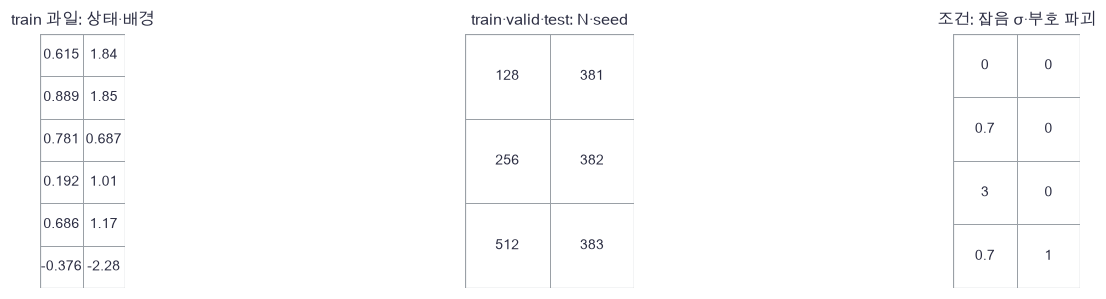

In [33]:
plot_panels([preview,plan,strength_plan],['train 과일: 상태·배경','train·valid·test: N·seed','조건: 잡음 σ·부호 파괴'])

🔍 **확인** · 변형 강도만 보지 말고 어떤 좌표를 바꾸는지 함께 읽으세요. 표본 수·배치·갱신·초기값을 맞춰도 서로 다른 학습 목적의 난도까지 같아지는 것은 아닙니다.

In [34]:
def make_fruits(n,seed,correlated):
    """상태 부호가 라벨이며 배경 상관만 분할마다 바뀌는 합성 과일입니다."""
    rng=np.random.default_rng(seed)
    state=rng.uniform(-1.,1.,n)
    labels=(state>0).astype(float)
    background=rng.normal(0.,.5,n)
    if correlated:
        background+=1.5*(2*labels-1)
    return np.column_stack([state,background]),labels[:,None]

In [35]:
def adam_step(p,grads,m,v,step,lr=.01):
    """Adam의 1·2차 모멘트와 bias 보정을 모든 배열에 적용합니다."""
    for name in p:
        m[name]=.9*m[name]+.1*grads[name]
        v[name]=.999*v[name]+.001*grads[name]**2
        mh=m[name]/(1-.9**step)
        vh=v[name]/(1-.999**step)
        p[name]-=lr*mh/(np.sqrt(vh)+1e-8)

In [36]:
def train_aug(X,y,valid,initial,strength,break_label=False):
    """같은 초기값·배치 순서·350 갱신으로 한 증강 조건을 학습합니다."""
    # 쓰는 것: bce_loss (4절) · draw_views (2절) · model_backward (4절) · model_forward (4절)
    # 1. 독립 배치·증강 난수와 optimizer 상태입니다.
    p={k:a.copy() for k,a in initial.items()}
    m={k:np.zeros_like(a) for k,a in p.items()}
    v={k:np.zeros_like(a) for k,a in p.items()}
    batch_rng=np.random.default_rng(384)
    aug_rng=np.random.default_rng(385)
    history=[]
    # 2. 데이터 변형 뒤 실제 손실을 미분하고 갱신합니다.
    for step in range(1,351):
        idx=batch_rng.integers(0,len(X),size=32)
        view,_=draw_views(X[idx],strength,aug_rng,break_label)
        logits,cache=model_forward(view,p)
        loss,dlogits=bce_loss(logits,y[idx])
        grads,_=model_backward(dlogits,cache,p)
        adam_step(p,grads,m,v,step)
        if step%50==0:
            val_logits,_=model_forward(valid[0],p)
            val_loss,_=bce_loss(val_logits,valid[1])
            history.append([step,val_loss])
    return p,np.array(history)

In [37]:
def evaluate_model(p,X,y):
    """관측별 CE·정확도와 은닉 표현 평균 분산을 별도 반환합니다."""
    # 쓰는 것: bce_loss (4절) · model_forward (4절)
    logits,cache=model_forward(X,p)
    loss,_=bce_loss(logits,y)
    accuracy=np.mean((logits>0)==y)
    return np.array([loss,accuracy,cache[1].var(axis=0).mean()])

In [38]:
# 쓰는 것: init_model (4절) · make_fruits (5절)
train_x,train_y=make_fruits(128,381,True)
valid_x,valid_y=make_fruits(256,382,False)
test_x,test_y=make_fruits(512,383,False)
initial=init_model(380,8)
settings=[('없음',0.,False),('약함',.7,False),('강함',3.,False),('라벨 파괴',.7,True)]
models=[]
histories=[]
for label,strength,bad in settings:
    fitted,history=train_aug(train_x,train_y,(valid_x,valid_y),initial,strength,bad)
    models.append(fitted)
    histories.append(history)
print('실제 파라미터 수',sum(a.size for a in initial.values()))

실제 파라미터 수 33


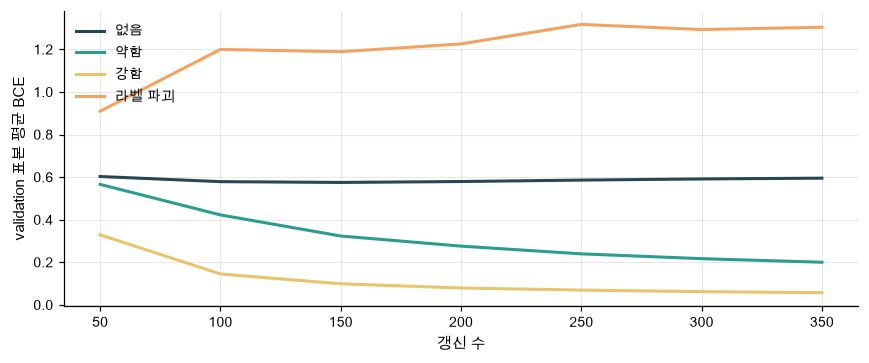

In [39]:
plot_curves(histories,[s[0] for s in settings],'validation 표본 평균 BCE')

In [40]:
# 쓰는 것: init_model (4절)
scores=np.array([evaluate_model(p,test_x,test_y) for p in models])
train_scores=np.array([evaluate_model(p,train_x,train_y) for p in models])
for (label,_,_),tr,te in zip(settings,train_scores,scores):
    print(label,'train 정확도',round(tr[1],3),'test [CE, 정확도, 평균 특징분산]',np.round(te,4))
assert np.isfinite(scores).all(), '독립 평가값이 모두 유한해야 합니다'
np.testing.assert_allclose(initial['W'],init_model(380,8)['W'])  # 검산: 동일 시작 모델은 학습 중 바뀌지 않음

없음 train 정확도 1.0 test [CE, 정확도, 평균 특징분산] [0.5053 0.7949 0.2062]
약함 train 정확도 1.0 test [CE, 정확도, 평균 특징분산] [0.1672 0.9375 0.3023]
강함 train 정확도 1.0 test [CE, 정확도, 평균 특징분산] [0.045  0.9961 0.3524]
라벨 파괴 train 정확도 1.0 test [CE, 정확도, 평균 특징분산] [1.1335 0.4883 0.1174]


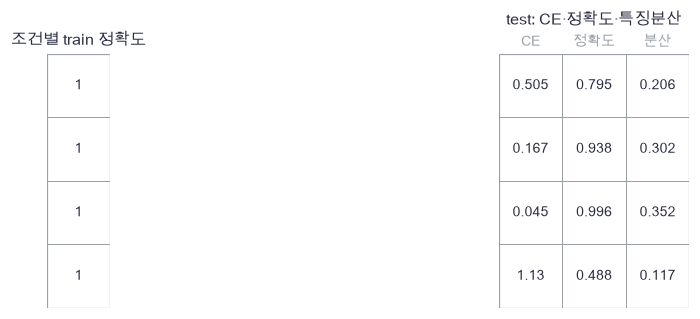

In [41]:
plot_panels([train_scores[:,1:2],scores],['조건별 train 정확도','test: CE·정확도·특징분산'],[None,['CE','정확도','분산']])

🔍 **확인** · 위의 출력이 이 고정 실험의 관측 결과입니다. 낮은 train 손실은 새로운 배경의 성공을 보장하지 않습니다. 분산이 크다고 라벨 정보가 많다는 뜻도 아닙니다. 라벨 파괴 조건의 저하는 잘못된 양성 쌍이 보존 정보를 없앨 수 있음을 보여 주는 진단이지 모든 실제 데이터에 대한 수치 예측은 아닙니다.

### ✏️ 연습 5 · 관측별 정확도 분모

0보다 큰 logit만 1로 분류하고 전체 관측의 정확도를 반환하세요.

In [42]:
def exercise_accuracy(logits,y):
    """0보다 큰 logit만 1로 분류하고 전체 관측의 정확도를 반환하세요."""

    ### 구현할 내용: 0보다 큰 logit만 1로 분류하고 전체 관측의 정확도를 반환하세요.
    raise NotImplementedError
    return acc

In [43]:
def check_accuracy(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[2.],[-1.],[0.],[3.]]),np.array([[1.],[0.],[1.],[0.]])),.5)  # 검산: 네 관측 중 둘 정답
    print("연습 5: 독립 기준값과 일치합니다.")

run_check(check_accuracy,exercise_accuracy,hint="0보다 큰 logit만 1로 분류하고 전체 관측의 정확도를 반환하세요.")

☐ exercise_accuracy: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 0보다 큰 logit만 1로 분류하고 전체 관측의 정확도를 반환하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
acc = np.mean((logits>0)==y)
```

</details>

## ✏️ 끝 연습 · 다른 축과 변형으로 검산합니다

### ✏️ 연습 A · 두 선형 변형의 순서

행 입력에 A 다음 B를 적용하세요. 순서를 바꾸지 마세요.

In [44]:
def exercise_compose(X,A,B):
    """행 입력에 A 다음 B를 적용하세요. 순서를 바꾸지 마세요."""

    ### 구현할 내용: 행 입력에 A 다음 B를 적용하세요. 순서를 바꾸지 마세요.
    raise NotImplementedError
    return Y

In [45]:
def check_compose(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,2.]]),np.diag([2.,1.]),np.array([[0.,1.],[1.,0.]])),[[2.,2.]])  # 검산: (1,2)→(2,2)→(2,2)
    np.testing.assert_allclose(candidate(np.array([[2.,3.]]),np.diag([2.,1.]),np.array([[0.,1.],[1.,0.]])),[[3.,4.]])  # 검산: (2,3)→(4,3)→(3,4)
    print("연습 A: 독립 기준값과 일치합니다.")

run_check(check_compose,exercise_compose,hint="행 입력에 A 다음 B를 적용하세요. 순서를 바꾸지 마세요.")

☐ exercise_compose: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 행 입력에 A 다음 B를 적용하세요. 순서를 바꾸지 마세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
Y = X@A@B
```

</details>

### ✏️ 연습 B · 세 뷰의 평균 예측

P:(V,N,1)의 뷰 축만 평균하여 관측별 확률을 만드세요.

In [46]:
def exercise_mean_view(P):
    """P:(V,N,1)의 뷰 축만 평균하여 관측별 확률을 만드세요."""

    ### 구현할 내용: P:(V,N,1)의 뷰 축만 평균하여 관측별 확률을 만드세요.
    raise NotImplementedError
    return mean_p

In [47]:
def check_mean_view(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[[0.],[1.]],[[1.],[0.]],[[.5],[.5]]])),[[.5],[.5]])  # 검산: 뷰 축만 평균
    print("연습 B: 독립 기준값과 일치합니다.")

run_check(check_mean_view,exercise_mean_view,hint="P:(V,N,1)의 뷰 축만 평균하여 관측별 확률을 만드세요.")

☐ exercise_mean_view: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: P:(V,N,1)의 뷰 축만 평균하여 관측별 확률을 만드세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
mean_p = P.mean(axis=0)
```

</details>

### ✏️ 연습 C · 입력과 라벨을 함께 재정렬

배치 행 순서를 바꾸면서 입력-정답 대응을 유지하세요.

In [48]:
def exercise_pair_permute(X,y,order):
    """배치 행 순서를 바꾸면서 입력-정답 대응을 유지하세요."""

    ### 구현할 내용: 배치 행 순서를 바꾸면서 입력-정답 대응을 유지하세요.
    raise NotImplementedError
    return pair

In [49]:
def check_pair_permute(candidate):
    """작은 독립 기준값과 비교합니다."""
    a,c=candidate(np.array([[1.],[2.],[3.]]),np.array([0,1,0]),np.array([1,2,0]))
    np.testing.assert_array_equal(a,[[2.],[3.],[1.]])  # 검산: 입력 순서
    np.testing.assert_array_equal(c,[1,0,0])  # 검산: 대응 라벨 유지
    print("연습 C: 독립 기준값과 일치합니다.")

run_check(check_pair_permute,exercise_pair_permute,hint="배치 행 순서를 바꾸면서 입력-정답 대응을 유지하세요.")

☐ exercise_pair_permute: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 배치 행 순서를 바꾸면서 입력-정답 대응을 유지하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
pair = (X[order],y[order])
```

</details>

### ✏️ 연습 D · 좌표마다 다른 변형 강도

X,E:(N,D)에 좌표별 scales:(D,)를 적용하세요. N·D가 달라도 같은 식입니다.

In [50]:
def exercise_different_noise(X,E,scales):
    """X,E:(N,D)에 좌표별 scales:(D,)를 적용하세요. N·D가 달라도 같은 식입니다."""

    ### 구현할 내용: X,E:(N,D)에 좌표별 scales:(D,)를 적용하세요. N·D가 달라도 같은 식입니다.
    raise NotImplementedError
    return view

In [51]:
def check_different_noise(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,2.,3.],[2.,3.,4.]]),np.ones((2,3)),np.array([0.,2.,-.5])),[[1.,4.,2.5],[2.,5.,3.5]])  # 검산: D=3의 열별 변형
    print("연습 D: 독립 기준값과 일치합니다.")

run_check(check_different_noise,exercise_different_noise,hint="X,E:(N,D)에 좌표별 scales:(D,)를 적용하세요. N·D가 달라도 같은 식입니다.")

☐ exercise_different_noise: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: X,E:(N,D)에 좌표별 scales:(D,)를 적용하세요. N·D가 달라도 같은 식입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
view = X+E*scales
```

</details>

### ✏️ 준비도 질문

- **설명:** 색·회전·순서 변형이 언제 라벨을 보존하나요? 양성 쌍과 안전한 변형은 왜 같지 않나요? → 1·2절
- **수식:** 불변·등변 식과 독립 두 잡음 차이의 기대 제곱값을 쓸 수 있나요? → 2·3절
- **구현:** 고정 변형 M,E를 지나 모든 파라미터와 입력까지 BCE를 미분할 수 있나요? → 4절
- **변형 검산:** 다른 D·뷰 수·배치 순서에서 축·정답 대응·평가 분모를 검사할 수 있나요? → 연습 B–D

### 📎 원전과 다음 연결

[SimCLR 원논문, Chen et al., 2020](https://proceedings.mlr.press/v119/chen20j.html)은 증강의 조합이 표현 학습 과제에 중요한 역할을 한다고 분석합니다. 여기의 2차원 지도학습 실험은 SimCLR 재현이 아닙니다. 39 InfoNCE에서는 같은 원본의 두 뷰를 실제 표현 목적에 넣고, 40 교사·학생에서는 타깃 표현의 갱신을 따로 다룹니다.